# Lab session 1

**Vanessa Gómez Verdejo,  Pablo Martínez Olmos, Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />


# Age Prediction from Face Images with PyTorch

Welcome to this hands-on lab! In this notebook, you will build and train deep learning models using PyTorch to solve a regression task: predicting a person’s age from facial images using the UTKFace dataset.

We’ll guide you through the process of building simple and advanced models, using modern deep learning practices, and integrating tools like PyTorch Lightning and MLflow to streamline development and monitor results.

**General Objective**: Familiarize yourself with PyTorch by constructing and training models for a regression task (age prediction from facial images), using simple architectures (MLP and CNN), data augmentation, and transfer learning.

<span style="color: blue;">Luis Manuel García Muñoz: comments in blue.</span>

<span style="color: blue;">Import libraries:</span>

In [1]:
import torch
from PIL import Image
from torch.utils.data import Dataset, random_split, DataLoader, TensorDataset, ConcatDataset
import numpy as np
import pytorch_lightning as pl
from torch.nn import MSELoss
from torch.nn import L1Loss
import matplotlib.pyplot as plt
import pandas as pd
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from torchinfo import summary
from IPython.display import clear_output
import torchvision.transforms.v2 as v2
import copy
from torchvision import models

IMAGES_PATH = '../Dataset/full_UTK_64x64.pt'
AGES_PATH = '../Dataset/full_ages_UTK.pt'

## 1. Dataset Setup

We will use the **UTKFace dataset**, a large collection of face images labeled with age (and other attributes).

The original UTKFace dataset can be downloaded from [Kaggle](https://www.kaggle.com/datasets/moritzm00/utkface-cropped?resource=download). However, to simplify preprocessing and reduce loading times, we provide two preprocessed versions of the dataset in the form of PyTorch tensors:

* The image tensors are stored in the file `full_UTK_64x64.pt`  containing all images at resolution 64x64.  To simplify and accelerate your experimentation.
* The corresponding age labels are provided in `full_ages_UTK.pt`, which align one-to-one with the image tensors.

The data is stored as preprocessed PyTorch tensors in `.pt` files. You won’t have to deal with raw image loading. Instead, your first task is to implement a custom PyTorch `Dataset` and prepare the corresponding **DataLoaders** for training, validation, and testing.

This class has to:
- Load preprocessed tensors.
- Scale pixel values to the [0, 1] range.
- Randomly split the dataset into **50% training**, **25% validation**, and **25% test**.
- Return images and corresponding ages as `float32`.

Once you instantiate the dataset, make sure to build the corresponding PyTorch **DataLoaders**, with appropriate batch sizes (e.g., 32 or 64) and shuffling for the training set.

Next, it's important to explore and visualize the dataset to gain some intuition about the task. Start by displaying a few sample images along with their corresponding ages to get a sense of the data quality and variability. Then, plot the distribution of ages across the dataset to understand whether it is balanced or skewed toward certain age ranges.


<span style="color: blue;">Custom dataset class: it allows us to read data from files.</span>

In [2]:

class CustomImageDataset(Dataset):
    def __init__(self, images_path, ages_path):

        self.images = torch.load(images_path).to(torch.float32)/255
        self.ages = torch.load(ages_path).to(torch.float32)
       
   
    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, idx):
        return self.images[idx], self.ages[idx]
       


<span style="color: blue;">We read data from files and store it in the dataset object.</span>

Age is 26.0


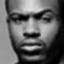

In [3]:

data = CustomImageDataset(IMAGES_PATH, AGES_PATH)

index = np.random.randint(len(data))

image, age = data[index]

print("Age is", age.item())

img = image.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
img = (img * 255).clip(0, 255).astype(np.uint8)

display(Image.fromarray(img))

<span style="color: blue;">We split the data in train, validation and test.</span>

In [4]:
n_total = len(data)

torch.manual_seed(1234)
pl.seed_everything(4567)

n_train = int(0.5 * n_total)
n_val = int(0.25 * n_total)
n_test = n_total - n_train - n_val

train_data, val_data, test_data = random_split(
    data,
    [n_train, n_val, n_test]
)

Seed set to 4567


## 2. Building a Simple MLP

With the data ready, your next task is to design a **Multilayer Perceptron (MLP)**. The architecture will serve as a baseline for later models. Here is the basic structure:

- Input: Flattened image tensor (e.g., for 64×64 images → 3 × 64 × 64 = 12288 input units)
- Hidden layer: 128 neurons, followed by a **ReLU** activation
- Output layer: A single neuron predicting a continuous value (the age)

Use `nn.MSELoss` as your training loss, and also compute the validation MSE (Mean Square Error) during during the training.

Wrap this model inside a `LightningModule`, and use the `LightningTrainer` to handle training loops. Don’t forget to implement:
- `training_step`, `validation_step`, and optionally `test_step`
- Optimizer configuration (e.g., Adam with learning rate 1e-3)

Train the model for **50 epochs** and log all key metrics using **MLflow**; for example, you can log training/validation loss. You can structure your logging using the built-in logger from PyTorch Lightning.

Later,  and plot some example predictions vs. ground truth.


After training, visualize and interpret your results:
- Analyze the training and validation loss curves.
- Compute training and test MSE and MAE (Mean Absolute Error) for interpretability
- Compare predicted vs. actual ages on a few test samples.
- Analyze how the model performs across different age ranges (e.g., is it worse for children or elderly faces?).


<span style="color: blue;">MLP Class.</span>

In [5]:
class SimpleMLP(torch.nn.Module):
    def __init__(self, num_features):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st hidden layer
            torch.nn.Linear(num_features, 128),
            torch.nn.ReLU(),
            # output layer
            torch.nn.Linear(128, 1),
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        y = self.all_layers(x)
        # question: torch.exp() can be used if we want to apply the exponential function to the output
        return y

<span style="color: blue;">Lit generic model. This wrapper will be used for every model we try.</span>

In [6]:
class LitGenericModel(pl.LightningModule):
    def __init__(self, model, loss, score ,lr=1e-3):
        super().__init__()
        self.save_hyperparameters(ignore=['model', 'loss', 'accuracy'])  # logs hyperparameters automatically

        self.model = model
        self.loss = loss
        self.score = score

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch):
        xs, ys = batch
        ys_estimate = self(xs)
        ys_estimate = ys_estimate.squeeze(1)
        loss = self.loss(ys_estimate, ys)
        acc = self.score(ys_estimate, ys)
  
        return loss, acc, ys_estimate, ys

    def training_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.train', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.train', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.valid', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.valid', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def test_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.test', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.test', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

<span style="color: blue;">We fit the MLP model. We also generate our data loaders that will be used for some of the remaining models.</span>

In [7]:
num_epochs = 50

model = SimpleMLP(3*64*64)

lit_model = LitGenericModel(model=model, loss=MSELoss(), score=L1Loss())

logger = CSVLogger(
    save_dir="lightning_logs",
    name="MLP",
    version="fixed"
)

trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=1,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger)

train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_data_loader = DataLoader(test_data, batch_size=64, shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)


/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/parsing.py:213: Attribute 'score' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['score'])`.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightni

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 273.65it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 268.27it/s, v_num=ixed]


<span style="color: blue;">The following helper function allows us to compute loss and score on the train, validation and test dataloders given a trainer and lit model objects previously trained.</span>

In [8]:
def evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader):

    train_metrics = trainer.validate(lit_model, dataloaders=train_data_loader, verbose=False)
    val_metrics  = trainer.validate(lit_model, dataloaders=valid_data_loader, verbose=False)   # logs 'acc.val', 'loss.val'
    test_metrics = trainer.test(lit_model,    dataloaders=test_data_loader, verbose=False)  # logs 'acc.test', 'loss.test'

    train_loss = train_metrics[0].get('loss.valid')
    val_loss = val_metrics[0].get('loss.valid')
    test_loss = test_metrics[0].get('loss.test')

    train_acc = train_metrics[0].get('score.valid')
    val_acc = val_metrics[0].get('score.valid')
    test_acc = test_metrics[0].get('score.test')

    metrics_df = pd.DataFrame(columns = ['loss', 'score'], index=['train', 'val', 'test'])
    metrics_df.loc['train'] = [train_loss, train_acc]
    metrics_df.loc['val'] = [val_loss, val_acc]
    metrics_df.loc['test'] = [test_loss, test_acc]

    clear_output(wait=False)

    return metrics_df



<span style="color: blue;">We obtain the metrics (loss and MAE) of the MLP model.</span>

In [9]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,score
train,168.452621,10.037458
val,203.291412,10.88305
test,206.9048,10.915681


<span style="color: blue;">As we can see in the previous table, we are suffering from slight variance (better results in train compared to validation and test).</span>

<span style="color: blue;">The following helper function will allow us to plot random images, print true and model predicted ages for the test dataset.</span>

In [10]:
def display_random_test_samples(test_data, lit_model, num_samples=10):
    lit_model.eval()

    for i in range(num_samples):  # Display random test samples
        index = np.random.randint(test_data.__len__())

        pred = lit_model(test_data[index][0].unsqueeze(0))

        print("Predicted age is ", pred.item())

        image, age = test_data[index]

        print("True age is ", age.item())

        img = image.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
        img = (img * 255).clip(0, 255).astype(np.uint8)

        display(Image.fromarray(img))



Predicted age is  43.294647216796875
True age is  35.0


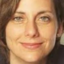

Predicted age is  41.77946472167969
True age is  43.0


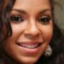

Predicted age is  49.252403259277344
True age is  38.0


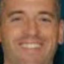

Predicted age is  49.162384033203125
True age is  24.0


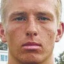

Predicted age is  44.74964904785156
True age is  53.0


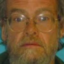

Predicted age is  8.651406288146973
True age is  3.0


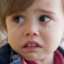

Predicted age is  34.460411071777344
True age is  85.0


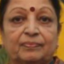

Predicted age is  58.46192932128906
True age is  45.0


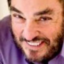

Predicted age is  56.00035095214844
True age is  36.0


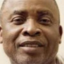

Predicted age is  76.44534301757812
True age is  38.0


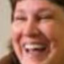

In [11]:
display_random_test_samples(test_data, lit_model)

<span style="color: blue;">Taking a look at the random images true and predicted ages, we see that the model makes worse predictions than those that a human would make (proxy of the bayes (irreducible) error). Therefore the model is suffering from both bias (bad prediction in validation and test) and slight variance (overfit), since metrics are better for train than for validation and test.</span>

<span style="color: blue;">This helper function allows us to plot the training path of both the loss ans the score (MAE).</span>

In [12]:
def plot_training_metrics(metrics_csv_path):
    train_metrics = pd.read_csv(metrics_csv_path)

    f, ax = plt.subplots(2,1, figsize=(10,8))
    train_epoch_metrics = train_metrics[["epoch", "score.train"]].dropna()
    valid_epoch_metrics = train_metrics[["epoch", "score.valid"]].dropna()

    ax[0].plot(train_epoch_metrics["epoch"], train_epoch_metrics["score.train"], marker="o", label="Train MAE")
    ax[0].plot(valid_epoch_metrics["epoch"], valid_epoch_metrics["score.valid"], marker="o", label="Validation MAE")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("MAE")
    ax[0].legend()
    ax[0].grid(True)
    train_loss_metrics = train_metrics[["epoch", "loss.train"]].dropna()
    valid_loss_metrics = train_metrics[["epoch", "loss.valid"]].dropna()

    ax[1].plot(train_loss_metrics["epoch"], train_loss_metrics["loss.train"], marker="o", label="Train Loss")
    ax[1].plot(valid_loss_metrics["epoch"], valid_loss_metrics["loss.valid"], marker="o", label="Validation Loss")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    ax[1].legend()
    ax[1].grid(True)

    plt.show()



<span style="color: blue;">We plot the training metrics of the MLP.</span>

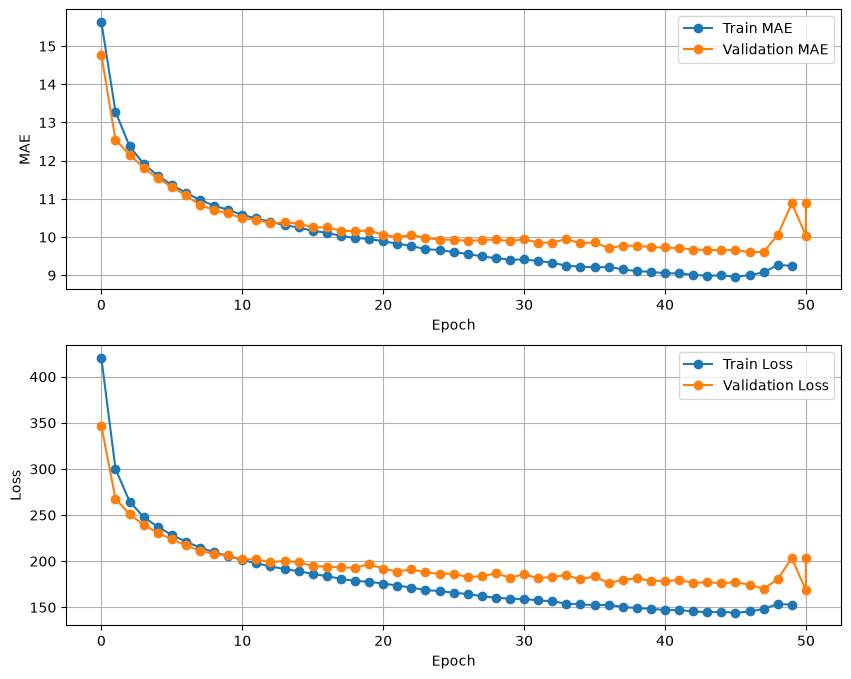

In [13]:
plot_training_metrics("lightning_logs/MLP/fixed/metrics.csv")


<span style="color: blue;">This helper function allows us to explore the model score for different age intervals.</span>

In [14]:
def evaluate_age_ranges(data, trainer, lit_model, date_range_lenth=10):

    max_age = np.ceil(data[0:][1].numpy().max()/10)*10
    print(max_age)

    age_ranges = np.arange(0, max_age + date_range_lenth, date_range_lenth)

    prop = []
    acc = []

    images, ages = data[0:]

    for i in range(len(age_ranges) - 1):
        mask = (ages >= age_ranges[i]) & (ages < age_ranges[i+1])

        data_in_range = TensorDataset(images[mask], ages[mask])
        data_loader = DataLoader(data_in_range, batch_size=32, shuffle=False)

        metrics = trainer.validate(lit_model, dataloaders=data_loader)

        prop.append(len(data_in_range) / len(data))
        acc.append(metrics[0].get("score.valid"))

    clear_output(wait=False)

    fig, ax1 = plt.subplots()
    color = 'tab:blue'
    ax1.set_xlabel('Age Range')
    ax1.set_ylabel('Accuracy', color=color)
    ax1.plot(age_ranges[:-1]+2.5, acc, color=color)
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Proportion', color=color)
    ax2.bar(age_ranges[:-1]+2.5, prop, color=color, alpha=0.3, width=4.5)
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()
    plt.title('Accuracy and Proportion by Age Range')
    plt.show()

<span style="color: blue;">We plot the score for different age intervals together with the proportion of the test dataset in those intervals.</span>

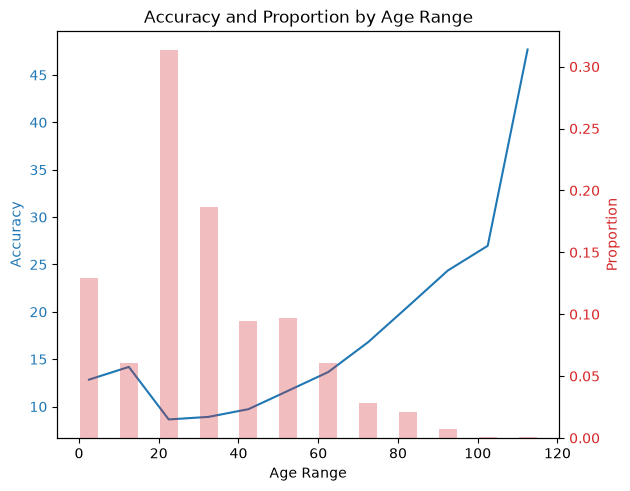

In [15]:
evaluate_age_ranges(test_data, trainer, lit_model)

<span style="color: blue;">As we can see in the previous chart, the proportion of data in the test dataset is greater for babies/todlers and people in the 20-40 range. The proportion dramatically decreases older ages. Better score (MAE) is obtained where the proportion of data is greater, although for babies and todlers results are worse than for the 20-40 range. For older ages the model performs badly.</span>

## 3. Convolutional Neural Networks (CNNs) for Age Prediction

In this part, you’ll move beyond fully connected layers and explore the power of **Convolutional Neural Networks (CNNs)** for image-based regression. CNNs are particularly well-suited to visual data, as they can exploit spatial hierarchies and local patterns more effectively than MLPs.

Your goal is to implement a simple CNN-based regressor and evaluate whether it outperforms the MLP from Part 2.

Thus, you will implement a CNN with the following structure:
- Two convolutional layers with 3×3 kernels and ReLU activation.
- 2×2 max pooling after each convolution to reduce spatial dimensions.
- A fully connected layer with 128 neurons.
- A final output layer predicting a single real value (age).

As before, implement the model using **PyTorch Lightning**, wrapping the architecture into a `LightningModule`. Train the model using the same loss function (`MSELoss`).

Once training is complete, perform a thorough evaluation of the CNN:
- Plot training and validation losses over time using **MLflow**. Note that you can now compare this run directly against your MLP results. Did it converge faster?
- Compute train and test MSE and MAE. Did the CNN achieve lower MAE or MSE than the MLP? Does it generalize better to unseen data?
- Compare again predicted vs. actual ages on a few test samples and analyze how the model performs across different age ranges.



<span style="color: blue;">Simple CNN class.</span>

In [16]:
class SimpleCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st cnn layer
            torch.nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Flatten(),
            torch.nn.LazyLinear(128),
            torch.nn.ReLU(),
            torch.nn.Linear(128,1)
        )

    def forward(self, x):
        y = self.all_layers(x)
        # question: torch.exp() can be used if we want to apply the exponential function to the output
        return y

<span style="color: blue;">We instanciate a CNN object and inspect different layers: parameters, and layer output size.</span>

In [17]:
model = SimpleCNN()

summary(model, input_size=(1,
     3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [1, 1]                    --
├─Sequential: 1-1                        [1, 1]                    --
│    └─Conv2d: 2-1                       [1, 16, 64, 64]           448
│    └─ReLU: 2-2                         [1, 16, 64, 64]           --
│    └─MaxPool2d: 2-3                    [1, 16, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 32, 32]           4,640
│    └─ReLU: 2-5                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-6                    [1, 32, 16, 16]           --
│    └─Flatten: 2-7                      [1, 8192]                 --
│    └─Linear: 2-8                       [1, 128]                  1,048,704
│    └─ReLU: 2-9                         [1, 128]                  --
│    └─Linear: 2-10                      [1, 1]                    129
Total params: 1,053,921
Trainable params: 1,053,921
Non-trainable params:

<span style="color: blue;">We train the CNN model.</span>

In [18]:
num_epochs = 50

model = SimpleCNN()

lit_model = LitGenericModel(model=model, loss=MSELoss(), score=L1Loss())

logger = CSVLogger(
    save_dir="lightning_logs",
    name="SimpleCNN",
    version="fixed"
)

trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=1,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger)

train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_data_loader = DataLoader(test_data, batch_size=64, shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/parsing.py:213: Attribute 'score' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['score'])`.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightni

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 49: 100%|██████████| 186/186 [00:01<00:00, 166.65it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 186/186 [00:01<00:00, 164.87it/s, v_num=ixed]


<span style="color: blue;">We evaluate the model, plot training metrics, evaluate the model for different ages and explore results for random images.</span>

In [19]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,score
train,28.542938,4.124872
val,114.158699,7.712062
test,117.032112,7.758043


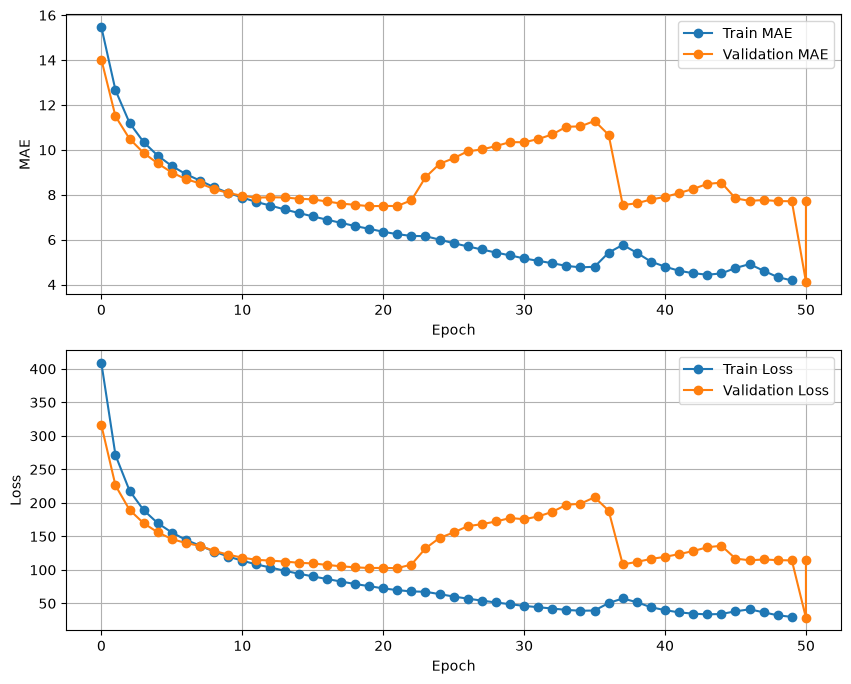

In [20]:
plot_training_metrics("lightning_logs/SimpleCNN/fixed/metrics.csv")

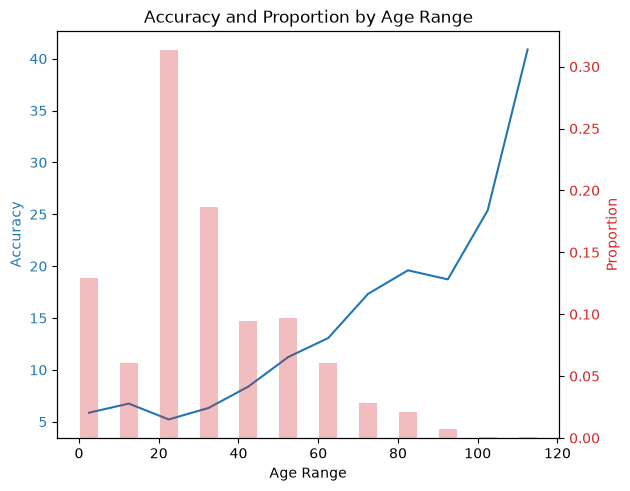

In [21]:
evaluate_age_ranges(test_data, trainer, lit_model)

Predicted age is  -6.0753936767578125
True age is  1.0


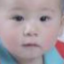

Predicted age is  38.26189422607422
True age is  41.0


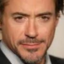

Predicted age is  33.67655563354492
True age is  35.0


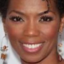

Predicted age is  35.89886474609375
True age is  35.0


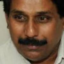

Predicted age is  71.41954803466797
True age is  45.0


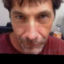

Predicted age is  23.47245979309082
True age is  23.0


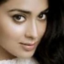

Predicted age is  32.19184494018555
True age is  35.0


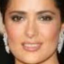

Predicted age is  46.954898834228516
True age is  74.0


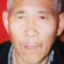

Predicted age is  28.661895751953125
True age is  33.0


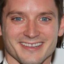

Predicted age is  33.71243667602539
True age is  24.0


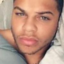

In [22]:
display_random_test_samples(test_data, lit_model)

<span style="color: blue;">The performance of the model (MAE approx 8 yrs in validation and test) has increased at the cost of a bigger overfit (MAE approx 4 yrs in train).</span>

## 4. Mitigating Overfitting in CNNs

In the previous section, you trained a CNN model for age prediction and likely observed signs of overfitting. This is a common issue when working with deeper models like CNNs, especially when data is limited.

To fully take advantage of the representational power of CNNs, you’ll now implement regularization strategies that help prevent overfitting and improve generalization.

In this part, your goal is to experiment with techniques that promote more robust learning:

You will extend your CNN architecture to include:

1.  **Dropout**: Randomly deactivates a fraction of neurons during training, reducing over-reliance on specific features. Include a dropout layer with a probaility of 0.25 before the final output (you can explore other probability values).

2.  **Batch Normalization**: Normalizes intermediate activations and helps stabilize learning, enabling faster convergence and acting as a form of regularization. Include BatchNorm layers after each convolution.

3. **Early Stopping**: Monitors validation loss and halts training when performance no longer improves, avoiding unnecessary overfitting. You can stop the training if the valiadtion error does not improve after 3 epochs.

As before, implement your model using PyTorch Lightning, and log all metrics and training curves with MLflow.

Once you’ve trained your regularized CNN, analyze its behavior and compare it to the version without regularization:

* Compare the training and validation loss curves for each individual strategy as well as for the combination of all strategies. Did overfitting reduce? Did the training process become more stable?

* Evaluate performance using MSE and MAE on the train, validation, and test sets.

* Discuss which regularization techniques were most effective.

<span style="color: blue;">The following class allows us to instanciate a CNN object with a given dropout and batch normalization option.</span>

In [23]:
class SimpleCNN_batchnorm_dropout(torch.nn.Module):
    def __init__(self, batch_norm=False, dropout=0.0):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st cnn layer
            torch.nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(16) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Dropout2d(dropout),
            torch.nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(32) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Dropout2d(dropout),
            torch.nn.Flatten(),
            torch.nn.LazyLinear(128),
            torch.nn.BatchNorm1d(128) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(128,1)
        )

    def forward(self, x):
        y = self.all_layers(x)
        return y

<span style="color: blue;">This helper function allows us to train the model for different batch norm, drop out and early stopping options.</span>

In [24]:
def train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader, valid_data_loader, 
            early_stopping = False, batch_norm=False, dropout=0.0,
            data_augment_callback = None):

    num_epochs = 50

    model = SimpleCNN_batchnorm_dropout(batch_norm=batch_norm, dropout=dropout)

    lit_model = LitGenericModel(model=model, loss=MSELoss(), score=L1Loss())

    logger = CSVLogger(
        save_dir="lightning_logs",
        name="CNN" + ("_BN" if batch_norm else "") + ("_DO" + str(dropout) if dropout > 0 else "") + ("_ES" if early_stopping else ""),
        version="fixed"
    )

    callbacks = []
    if early_stopping:
        callbacks.append(EarlyStopping(monitor="loss.valid", patience=3, mode="min"))
    if data_augment_callback is not None:
        callbacks.append(data_augment_callback)

    trainer =  pl.Trainer(max_epochs=num_epochs,
        log_every_n_steps=1,
        deterministic=True,     # aim for reproducibility where possible
        accelerator="auto",     # use GPU if available
        devices="auto",
        logger=logger,
        callbacks=callbacks)


    trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)

    clear_output(wait=False)
    
    return trainer, lit_model


<span style="color: blue;">No batch normalization, early stopping, no drop out.</span>

In [25]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader, 
            valid_data_loader, early_stopping=True, batch_norm=False, dropout= 0.0)

evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,score
train,90.377861,7.271684
val,121.207466,8.273529
test,126.492348,8.455359


<span style="color: blue;">With early stopping, we reduce the overfit. However test metrics are similar (slightly worse) to the previous model</span>

<span style="color: blue;">No early stopping, batch norm and no dropout.</span>

In [26]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader, 
            valid_data_loader, early_stopping=False, batch_norm=True, dropout= 0.0)

evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,score
train,28.274595,4.002807
val,120.809845,8.232018
test,126.958168,8.266562


<span style="color: blue;">No improvement with batch norm in isolation.</span>

<span style="color: blue;">We test dropout with different probabilities and early stopping.</span>

In [27]:
dropout_probs = [0.2, 0.25, 0.3]

metrics = [] 

for dropout_prob in dropout_probs:

    print(f"Training with dropout probability: {dropout_prob}")

    trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader,
         valid_data_loader, early_stopping=True, batch_norm=False, dropout=dropout_prob)
    metrics_df = evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)
    metrics.append(metrics_df)

    clear_output(wait=False)
  



In [28]:
for m, p in zip(metrics, dropout_probs):
    print(f"Results for dropout probability: {p}")
    display(m)

Results for dropout probability: 0.2


,loss,score
train,64.463844,5.93476
val,103.820137,7.391411
test,111.255333,7.453099


Results for dropout probability: 0.25


,loss,score
train,94.387962,7.091572
val,117.023743,7.856029
test,127.005142,7.999352


Results for dropout probability: 0.3


,loss,score
train,99.039986,7.223721
val,119.925896,7.879323
test,126.134308,7.949247


<span style="color: blue;">Model performance has clearly improved with drop out. Best results obtained with 0.2 dropout prob.</span>

<span style="color: blue;">We test the three together (drop out, batch normalization and early stopping).</span>

In [29]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader, 
            valid_data_loader, early_stopping=True, batch_norm=True, dropout= 0.2)

evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,score
train,49.139912,5.250088
val,104.57914,7.597108
test,112.507393,7.720242


<p style="color: blue;">Similar results as the drop out model at the cost of greater overfit. However training process is accelerated. We will use this model for later.</p>

## 5. Data Augmentation to Improve Generalization

In this section, you will explore **Data Augmentation** as a technique to reduce overfitting, especially when training deep models on relatively small datasets. Data Augmentation artificially increases the diversity of the training data by applying random transformations to the original images. This helps the model become more robust by exposing it to a wider variety of visual scenarios during training.

Common image transformations include:

- **Rotation**: Randomly rotating the image by a few degrees.
- **Horizontal Flip**: Mirroring the image to simulate left/right variation.
- **Brightness and Contrast Adjustment**: Introducing lighting variability.
- **Random Resized Crop**: Cropping random portions of the image and resizing them, encouraging the model to focus on multiple parts of the object.

These augmentations help the model generalize better by reducing its reliance on specific patterns or image positions.

We will use the `torchvision.transforms.v2` module to apply these transformations. A typical transformation pipeline might look like this:

```python
import torchvision.transforms.v2 as v2

transform = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(20),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.RandomResizedCrop(64, scale=(0.8, 1.0)),
])
```

You should now update your custom dataset class to apply these transformations to the training data only. Then, define new DataLoaders for training, validation, and test sets accordingly.

**Use the best model from the previous section** (i.e., your CNN including the best regularization strategies like dropout, batch normalization, and early stopping) and train it again using the augmented data. Compare its performance to the previous version trained without augmentation.

**Discussion**: Try different combinations of transformations and vary their parameters (e.g., rotation angle, brightness factor, scale range). Discuss which ones seem most appropriate for this task and why. Are there any transformations that seem to harm performance or introduce unrealistic samples?

<p style="color: blue;">Data augmented dataset class. Instead of loading data from files, we retrieve it from the training dataset being used.</p>

In [30]:

class DataAugmentDataset(Dataset):
    def __init__(self, norm_images, ages, rot_angle, brightness, contrast, crop_scale):

        self.transform = v2.Compose([
            v2.RandomHorizontalFlip(),
            v2.RandomRotation(rot_angle),
            v2.ColorJitter(brightness=brightness, contrast=contrast),
            v2.RandomResizedCrop(64, scale=crop_scale),
        ])

        self.images = norm_images
        self.ages = ages

    def refresh_trasformation(self):
        self.train_images = self.transform(self.images)

    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, idx):
        return self.train_images[idx], self.ages[idx]

class RefreshAugmentation(pl.Callback):
    def on_train_epoch_start(self, trainer, pl_module):
        dataset = trainer.train_dataloader.dataset
        dataset.refresh_trasformation()  

<span style="color: blue;">We instanciate the augmented dataset and explore the transformation.</span>

True age is  39.0
Original image


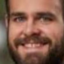

Augmented image


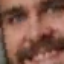

Augmented image 2


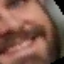

In [31]:
train_data_augmented = DataAugmentDataset(
    norm_images=train_data.dataset.images[train_data.indices],
    ages=train_data.dataset.ages[train_data.indices],
    rot_angle=45,
    brightness=0.2,
    contrast=0.2,
    crop_scale=(0.4, 0.4),
)

train_data_augmented.refresh_trasformation()

index = np.random.randint(len(train_data_augmented))

image, age = train_data[index]

image_aug, age = train_data_augmented[index]

print("True age is ", age.item())

print("Original image")
img = image.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
img = (img * 255).clip(0, 255).astype(np.uint8)
display(Image.fromarray(img))


print("Augmented image")
img_aug = image_aug.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
img_aug = (img_aug * 255).clip(0, 255).astype(np.uint8)

display(Image.fromarray(img_aug))

train_data_augmented.refresh_trasformation()

image_aug, age = train_data_augmented[index]

print("Augmented image 2")
img_aug = image_aug.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
img_aug = (img_aug * 255).clip(0, 255).astype(np.uint8)

display(Image.fromarray(img_aug))


<span style="color: blue;">We first test with a random angle transformation from (-20, 20) .</span>

In [32]:
train_data_augmented = DataAugmentDataset(
    norm_images=train_data.dataset.images[train_data.indices],
    ages=train_data.dataset.ages[train_data.indices],
    rot_angle=20,
    brightness=0.0,
    contrast=0.0,
    crop_scale=(1.0, 1.0),
)

train_data_loader_aug = DataLoader(train_data_augmented, batch_size=32, shuffle=True)

trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader_aug, 
            valid_data_loader, early_stopping=True, batch_norm=True, dropout= 0.25,
            data_augment_callback=RefreshAugmentation())

metrics_df = evaluate_model(trainer, lit_model, train_data_loader_aug, valid_data_loader, test_data_loader)

print("Number of epochs trained: ", trainer.current_epoch)

metrics_df

Number of epochs trained:  13


,loss,score
train,128.515686,8.389667
val,139.722763,8.838246
test,151.054459,9.062828


<span style="color: blue;">Model performance worsens attributable to great difference in train and validation / test since these images are not rotated.</span>

<span style="color: blue;">Let us test change brightness and contrast (0.8, 1.2).</span>

In [33]:
train_data_augmented = DataAugmentDataset(
    norm_images=train_data.dataset.images[train_data.indices],
    ages=train_data.dataset.ages[train_data.indices],
    rot_angle=0,
    brightness=0.2,
    contrast=0.2,
    crop_scale=(1.0, 1.0),
)

train_data_loader_aug = DataLoader(train_data_augmented, batch_size=32, shuffle=True)

trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader_aug, 
            valid_data_loader, early_stopping=True, batch_norm=True, dropout= 0.25,
            data_augment_callback=RefreshAugmentation())

metrics_df = evaluate_model(trainer, lit_model, train_data_loader_aug, valid_data_loader, 
                            test_data_loader)

print("Number of epochs trained: ", trainer.current_epoch)

metrics_df

Number of epochs trained:  9


,loss,score
train,88.674751,7.04672
val,113.891411,8.03043
test,124.181099,8.339877


<span style="color: blue;">Model performance worsens slightly with respect to no data augmentation.</span>


<span style="color: blue;">Random cropping with 0.8 scale.</span>

In [34]:
train_data_augmented = DataAugmentDataset(
    norm_images=train_data.dataset.images[train_data.indices],
    ages=train_data.dataset.ages[train_data.indices],
    rot_angle=0,
    brightness=0.0,
    contrast=0.0,
    crop_scale=(0.8, 0.8),
)

train_data_loader_aug = DataLoader(train_data_augmented, batch_size=32, shuffle=True)

trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(train_data_loader_aug, 
            valid_data_loader, early_stopping=True, batch_norm=True, dropout= 0.25,
            data_augment_callback=RefreshAugmentation())

metrics_df = evaluate_model(trainer, lit_model, train_data_loader_aug, valid_data_loader, test_data_loader)

print("Number of epochs trained: ", trainer.current_epoch)

metrics_df

Number of epochs trained:  11


,loss,score
train,126.881477,8.467847
val,204.244522,11.452209
test,210.794479,11.586761




## 6. Data Augmentation for Balancing Age Ranges

As you likely noticed, the dataset may be imbalanced across different age ranges, which could lead to your model performing worse on underrepresented groups (e.g., older individuals). To help balance the data, we will use data augmentation to generate additional images for underrepresented age ranges.

**Strategy for Balancing the Dataset**:

- Analyze underrepresented age groups: First, you need to check the distribution of ages across the dataset to identify which age groups are underrepresented. You can use age groups in intervals of 10 years.

- Generate additional images for these age groups: Make copies of the data within each range to have a minimum of 2000 or 3000 samples per age group, so that the distribution becomes more homogeneous across all ranges.

- Generate diversity: Modify the code so that when loading each sample (in the dataset __getitem__), the samples are randomly modified to generate diversity among them, using the transformations defined earlier.

Retrain the CNN model with this extended dataset and verify that by generating more data for underrepresented age ranges, your model will not be biased towards ages with more training data.


In [35]:

max_age = np.ceil(data[0:][1].numpy().max()/10)*10
print(max_age)

age_ranges = np.arange(0, max_age + 10 , 10)

print(age_ranges)

images, ages = train_data[0:]


num_in_ranges = [ages[(ages >= age_ranges[i]) & (ages < age_ranges[i+1])].shape[0] for i in range(len(age_ranges) - 1)]
print(num_in_ranges)


120.0
[  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100. 110. 120.]
[1515, 792, 3696, 2254, 1133, 1128, 656, 352, 244, 65, 10, 7]


In [36]:
DATA_IN_RANGE = 4000

images, ages = train_data[:]
balanced_indices = [torch.arange(len(ages))]

for lower, upper in zip(age_ranges[:-1], age_ranges[1:]):
    indices = torch.where((ages >= lower) & (ages < upper))[0]
    num_additional = DATA_IN_RANGE - len(indices)
    if len(indices) > 0 and num_additional > 0:
        sampled_indices = indices[torch.randint(len(indices), (num_additional,))]
        balanced_indices.append(sampled_indices)

balanced_indices = torch.cat(balanced_indices)
train_data_balanced = TensorDataset(
    images[balanced_indices], ages[balanced_indices]
)


In [37]:
images_balanced, ages_balanced = train_data_balanced[:]

num_in_ranges_balanced = [
    ((ages_balanced >= lower) & (ages_balanced < upper)).sum().item()
    for lower, upper in zip(age_ranges[:-1], age_ranges[1:])
]
print(num_in_ranges_balanced)


[4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000]


In [38]:
train_data_balanced_augmented = DataAugmentDataset(
    norm_images=images_balanced,
    ages=ages_balanced,
    rot_angle=0,
    brightness=0.2,
    contrast=0.2,
    crop_scale=(1.0, 1.0),
)
balanced_augmented_data_loader = DataLoader(train_data_balanced_augmented, batch_size=64, shuffle=True)

trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(balanced_augmented_data_loader, 
            valid_data_loader, early_stopping=True, batch_norm=True, dropout= 0.25,
            data_augment_callback=RefreshAugmentation())

metrics_df = evaluate_model(trainer, lit_model, balanced_augmented_data_loader, valid_data_loader, test_data_loader)

print("Number of epochs trained: ", trainer.current_epoch)

metrics_df

Number of epochs trained:  8


,loss,score
train,55.224358,5.767564
val,125.962822,8.535193
test,128.485214,8.625167


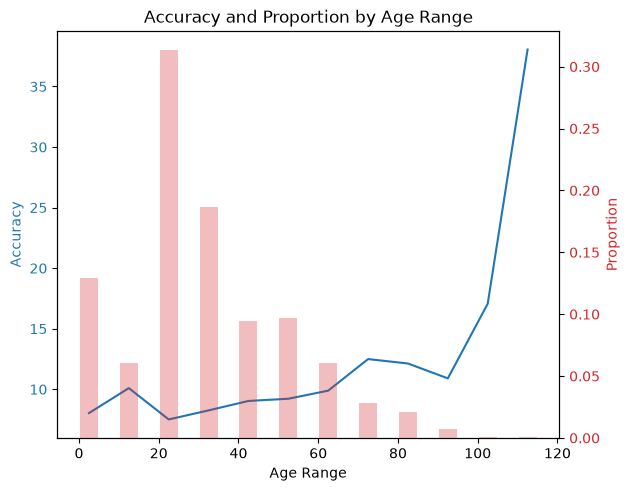

In [41]:
evaluate_age_ranges(test_data, trainer, lit_model, 10)

## 6. Transfer Learning with Pretrained Models

In this final part of the lab, you will explore **transfer learning**, a powerful technique that uses pre-trained models to solve new tasks more efficiently. The idea is to start from a deep neural network that has already been trained on a large dataset (such as ImageNet), and adapt it to your current problem—in this case, **predicting age from facial images**.

You will work with the **ResNet18** architecture, available through `torchvision.models`. ResNet18 is a CNN composed of residual blocks and approximately 11 million parameters. It was originally trained on the **ImageNet** dataset, which contains over 1 million images across 1000 categories. Thanks to its learned filters and representations, ResNet18 can serve as a powerful **feature extractor** for a wide range of visual tasks, including regression.

Adapt ResNet18 to perform age regression and compare its performance with the models implemented in previous parts.

Specifically, you will:

- **Load ResNet18 pre-trained on ImageNet** using `torchvision.models.resnet18(pretrained=True)`.

- **Modify the last layer** of the model to output a single value (age), instead of 1000 classification logits. The original final layer is:
  ```python
  model.fc = nn.Linear(512, 1000)
  ```
  You will replace it with:
  ```python
  model.fc = nn.Linear(512, 1)
  ```

- **Data transformation**: ResNet18 expects input images with shape 3×224×224 (RGB format) and normalized pixel values, ensure that your images are correctly resized and normalized to match the format expected by the model. You can use this transformation directly when preparing your dataset:
```python
 transforms = [
    v2.Resize((IMG_SIZE_resnet, IMG_SIZE_resnet)),  # Resize to 224x224 for ResNet
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize with ImageNet stats
]  
```

- **Try two training strategies**:
  1. **Feature extraction (freeze all convolutional layers)**: This approach uses the learned representations from ImageNet as fixed features, and only updates the final regression head.
     To freeze the backbone, use:
     ```python
     for param in self.feature_extractor.parameters():
                param.requires_grad = False
     ```
  2. **Fine-tuning**: After training the regression head for a few epochs, you can **unfreeze the full network** and train all layers together with a lower learning rate, adapting all parameters to the age regression task.

As before, you will wrap your model in a **PyTorch LightningModule**, train it using `MSELoss`, and evaluate its performance using **MAE and MSE**. You can try to use any regularization strategy and data augmentation to improve the model performance.

Finally, compare your ResNet18 runs to previous models and analyze whether transfer learning improves generalization.

Note: ResNet18 expects input images with shape 3×224×224 (RGB format) and normalized pixel values. Fortunately, the pretrained ResNet models from torchvision.models come with a predefined preprocessing pipeline (weights.transforms()), which ensures that your images are correctly resized and normalized to match the format expected by the model. You can use this transformation directly when preparing your dataset.

In [42]:
# Transform one image at a time; never resize the entire dataset in memory.
class ResNetInputDataset(Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, age = self.dataset[idx]
        return self.transform(image), age


class ResNet18Dataset(ResNetInputDataset):
    def __init__(self, norm_images, ages, rot_angle=0, brightness=0.2,
                 contrast=0.2, crop_scale=(1.0, 1.0)):
        transform = v2.Compose([
            v2.RandomHorizontalFlip(),
            v2.RandomRotation(rot_angle),
            v2.ColorJitter(brightness=brightness, contrast=contrast),
            v2.RandomResizedCrop(224, scale=crop_scale, ratio=(1.0, 1.0),
                                 antialias=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
        ])
        super().__init__(TensorDataset(norm_images, ages), transform)


class LitFrozenResNet(LitGenericModel):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Set the mode before Lightning saves/restores it for sanity validation.
        self.train()

    def train(self, mode=True):
        super().train(mode)
        # Freezing parameters does not freeze BatchNorm running statistics.
        # Keep the pretrained backbone in evaluation mode during head training.
        self.model.eval()
        self.model.fc.train(mode)
        return self

    def configure_optimizers(self):
        return torch.optim.Adam(
            (p for p in self.parameters() if p.requires_grad),
            lr=self.hparams.lr,
        )


In [43]:
resnet18model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_features = resnet18model.fc.in_features
resnet18model.fc = torch.nn.Linear(num_features, 1)

summary(resnet18model, input_size=(1,
     3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

In [44]:
for name, param in resnet18model.named_parameters():
    if not name.startswith("fc"):
        param.requires_grad = False

In [45]:
from time import perf_counter
from pytorch_lightning.callbacks import TQDMProgressBar

# The input tensors already contain RGB floats in [0, 1].
# Augmentation is applied per sample, so no RefreshAugmentation callback is needed.
resnet18_dataset = ResNet18Dataset(
    norm_images=images_balanced,
    ages=ages_balanced,
    rot_angle=0,
    brightness=0.2,
    contrast=0.2,
    crop_scale=(1.0, 1.0),
)
resnet_eval_transform = v2.Compose([
    v2.Resize((224, 224), antialias=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Keep validation/test batches small too. num_workers=0 works with notebook classes.
resnet_batch_size = 32
train_data_loader_resnet = DataLoader(
    resnet18_dataset, batch_size=resnet_batch_size, shuffle=True, num_workers=0,
)
valid_data_loader_resnet = DataLoader(
    ResNetInputDataset(val_data, resnet_eval_transform),
    batch_size=resnet_batch_size, shuffle=False, num_workers=0,
)
test_data_loader_resnet = DataLoader(
    ResNetInputDataset(test_data, resnet_eval_transform),
    batch_size=resnet_batch_size, shuffle=False, num_workers=0,
)
resnet18_dataloader = train_data_loader_resnet

print("Checking the first transformed batch...", flush=True)
started = perf_counter()
xs, ys = next(iter(train_data_loader_resnet))
assert xs.shape[1:] == (3, 224, 224)
assert torch.isfinite(xs).all() and torch.isfinite(ys).all()
print(f"Batch {tuple(xs.shape)} ready in {perf_counter() - started:.2f}s. "
      f"{len(train_data_loader_resnet)} training batches per epoch.", flush=True)
del xs, ys

lit_model = LitFrozenResNet(model=resnet18model, loss=MSELoss(), score=L1Loss())
logger = CSVLogger(save_dir="lightning_logs", name="ResNet18Frozen")
callbacks = [
    EarlyStopping(monitor="loss.valid", patience=3, mode="min"),
    TQDMProgressBar(refresh_rate=1),
]
trainer = pl.Trainer(
    max_epochs=num_epochs,
    log_every_n_steps=10,
    deterministic=True,
    accelerator="auto",
    devices=1,
    logger=logger,
    callbacks=callbacks,
    enable_progress_bar=True,
    num_sanity_val_steps=2,
)
print(f"Starting ResNet training on {trainer.strategy.root_device}.", flush=True)
trainer.fit(
    lit_model,
    train_dataloaders=train_data_loader_resnet,
    val_dataloaders=valid_data_loader_resnet,
)
# Keep the training output visible for timing and diagnosis.


Checking the first transformed batch...
Batch (32, 3, 224, 224) ready in 0.03s. 1500 training batches per epoch.


/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/parsing.py:213: Attribute 'score' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['score'])`.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Starting ResNet training on mps:0.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | ResNet  | 11.2 M | eval  | 0    
1 | loss  | MSELoss | 0      | train | 0    
2 | score | L1Loss  | 0      | train | 0    
--------------------------------------------------
513       Trainable params
11.2 M    Non-trainable params
11.2 M    Total params
44.708    Total estimated model params size (MB)
3         Modules in train mode
67        Modules in eval mode
0         Total Flops


/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:538: Found 67 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


Epoch 22: 100%|██████████| 1500/1500 [00:34<00:00, 43.89it/s, v_num=0]  


In [ ]:
# Evaluate using the same deterministic preprocessing as validation.
trainer.test(lit_model, dataloaders=test_data_loader_resnet)
